# 02 · Análise exploratória (EDA) e features territoriais

**Objetivo:** entender **onde a ocasião de pizza acontece** e **quanto o Guaraná já está nela**, antes de qualquer modelo.
A EDA serve para três coisas:
1. Validar as hipóteses de negócio do TAPI (sexta a domingo, noite, em casa, classe A).
2. Decidir quais features fazem sentido (Passo 5 da aula: "relação de cada feature com o target").
3. Gerar os **números do Decision Engine**: taxa de pizza, attach de refrigerante e share de Guaraná por segmento.

> **Regra importante:** a POF tem menos registros de sexta e sábado (desenho da coleta). Por isso comparamos sempre **taxas** (% de ocasiões com pizza), nunca contagens.
>
> Todas as taxas usam o **peso amostral** (`peso`), para representar a população brasileira e não só a amostra.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

base = pd.read_parquet(ROOT / "data" / "processed" / "base_ocasioes.parquet")
print(base.shape)

# Estilo dos gráficos: traços finos, grade discreta, uma cor por papel
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "text.color": "#0b0b0b", "axes.labelcolor": CINZA,
    "xtick.color": CINZA, "ytick.color": CINZA,
})

(363412, 31)


## 1. Função de resumo por segmento

Para cada segmento calculamos:
- `taxa_pizza`: % das ocasiões que tiveram pizza → **onde a ocasião acontece**
- `attach_refri`: % das ocasiões de pizza com refrigerante → **o refrigerante já acompanha?**
- `share_guarana`: % das ocasiões pizza + refri em que o refri é guaraná → **o Guaraná já é o escolhido?**
- `n_pizza`: quantas ocasiões de pizza sustentam o número. **Abaixo de ~50, trate como indício, não conclusão.**

In [2]:
def media_ponderada(df, col):
    if len(df) == 0 or df["peso"].sum() == 0:
        return np.nan
    return np.average(df[col], weights=df["peso"])


def resumo(df, por):
    linhas = []
    for chave, g in df.groupby(por, observed=True):
        pz = g[g["y_pizza"] == 1]
        pr = pz[pz["tem_refri"] == 1]
        linhas.append({
            **(dict(zip(por, chave)) if isinstance(por, list) else {por: chave}),
            "ocasioes": len(g),
            "n_pizza": len(pz),
            "taxa_pizza": media_ponderada(g, "y_pizza"),
            "attach_refri": media_ponderada(pz, "tem_refri"),
            "share_guarana": media_ponderada(pr, "tem_guarana"),
        })
    return pd.DataFrame(linhas)


fmt = {"taxa_pizza": "{:.2%}", "attach_refri": "{:.1%}", "share_guarana": "{:.1%}"}
geral = resumo(base.assign(todos="Brasil"), "todos")
geral.style.format(fmt)

,todos,ocasioes,n_pizza,taxa_pizza,attach_refri,share_guarana
0,Brasil,363412,1711,0.63%,33.5%,29.4%


## 2. Quando: dia da semana × período do dia

Esse cruzamento **é o baseline obrigatório do TAPI** ("frequência histórica por dia da semana e período do dia").
Se o modelo do notebook 03 não superar essa tabela, ele não aprendeu nada útil.

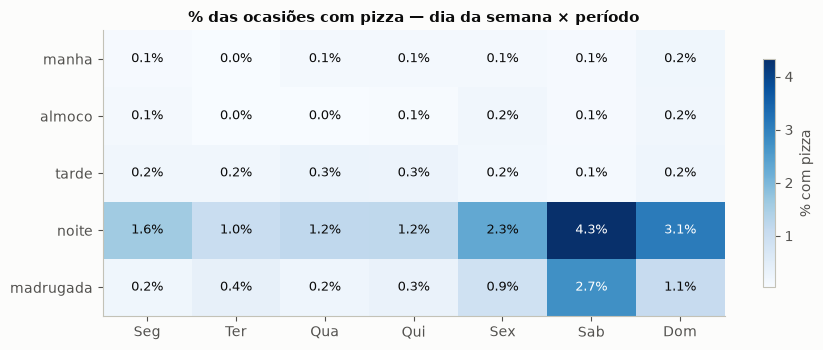

In [3]:
ORDEM_DIAS = ["Segunda-Feira", "Terca-Feira", "Quarta-Feira", "Quinta-Feira", "Sexta-Feira", "Sabado", "Domingo"]
ORDEM_PER = ["manha", "almoco", "tarde", "noite", "madrugada"]

tab = resumo(base[base.periodo != "indefinido"], ["dia_semana", "periodo"])
mapa = tab.pivot(index="periodo", columns="dia_semana", values="taxa_pizza").loc[ORDEM_PER, ORDEM_DIAS]

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(mapa.values * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(7), [d.split("-")[0][:3] for d in ORDEM_DIAS])
ax.set_yticks(range(len(ORDEM_PER)), ORDEM_PER)
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j] * 100
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
                color="white" if v > np.nanmax(mapa.values) * 60 else "#0b0b0b")
ax.set_title("% das ocasiões com pizza — dia da semana × período")
fig.colorbar(im, ax=ax, label="% com pizza", shrink=0.8)
plt.tight_layout()
plt.show()

**Leitura:** a noite concentra a pizza, e o pico é **sábado e domingo à noite**, como o TAPI descreve.
Mas há pizza também em outros momentos — o baseline captura só esse padrão "óbvio"; o modelo precisa achar o que vai **além** dele (quem, onde, com quem).

## 3. Quem e onde: taxa de pizza por segmento

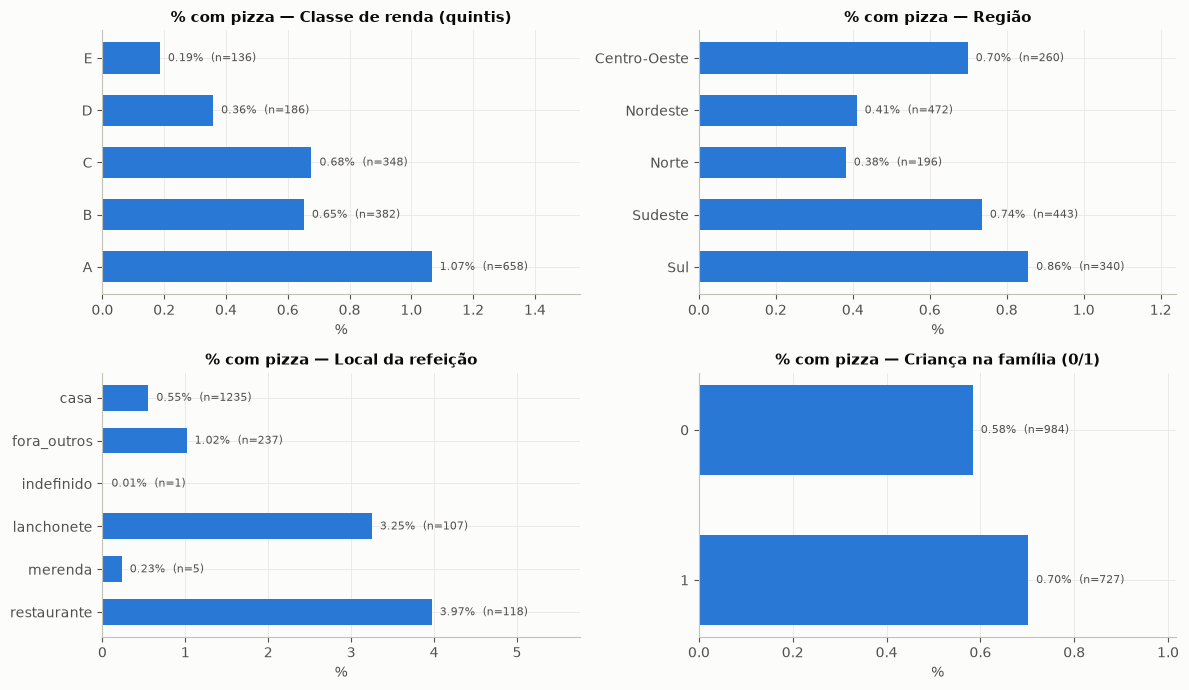

In [4]:
def barras(ax, df, col, rotulo, titulo, cor=AZUL, pct_dec=1):
    df = df.reset_index(drop=True)
    ax.barh(df[rotulo].astype(str), df[col] * 100, color=cor, height=0.6)
    for i, (v, n) in enumerate(zip(df[col] * 100, df["n_pizza"])):
        if not np.isnan(v):
            ax.text(v, i, f"  {v:.{pct_dec}f}%  (n={n})", va="center", fontsize=8, color=CINZA)
    ax.set_title(titulo)
    ax.set_xlabel("%")
    ax.set_xlim(0, np.nanmax(df[col]) * 100 * 1.45)
    ax.invert_yaxis()


segmentos = {
    "classe_renda": "Classe de renda (quintis)",
    "regiao": "Região",
    "local": "Local da refeição",
    "tem_crianca": "Criança na família (0/1)",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (seg, titulo) in zip(axes.flat, segmentos.items()):
    r = resumo(base, seg)
    if seg == "local":
        r = r[r["ocasioes"] > 1000]
    barras(ax, r, "taxa_pizza", seg, f"% com pizza — {titulo}", pct_dec=2)
plt.tight_layout()
plt.show()

**Leitura:**
- **Renda** é o fator mais forte depois do horário: a classe A tem ~5× a taxa da classe E (confirma o TAPI).
- **Sul e Sudeste** à frente; Norte e Nordeste abaixo.
- **Fora de casa** (restaurante, lanchonete) a taxa é maior por ocasião — mas em volume, a grande maioria da pizza é **em casa** (onde está o delivery).
- Famílias com criança têm taxa um pouco maior.

## 4. O Guaraná dentro da ocasião: attach e share

Aqui está o coração do problema de negócio. **Onde a pizza acontece, o Guaraná está presente?**

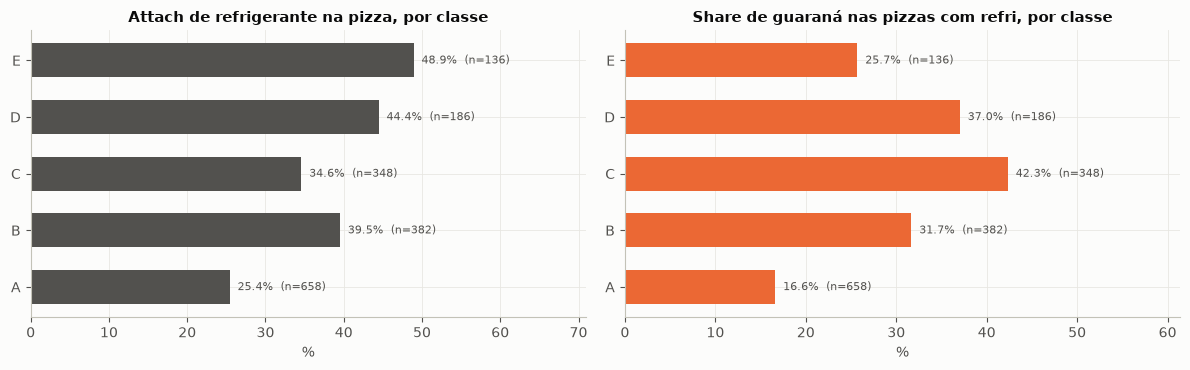

,classe_renda,ocasioes,n_pizza,taxa_pizza,attach_refri,share_guarana
0,E,72679,136,0.19%,48.9%,25.7%
1,D,72656,186,0.36%,44.4%,37.0%
2,C,72643,348,0.68%,34.6%,42.3%
3,B,72658,382,0.65%,39.5%,31.7%
4,A,72658,658,1.07%,25.4%,16.6%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
r = resumo(base, "classe_renda")
barras(axes[0], r, "attach_refri", "classe_renda", "Attach de refrigerante na pizza, por classe", cor=CINZA)
barras(axes[1], r, "share_guarana", "classe_renda", "Share de guaraná nas pizzas com refri, por classe", cor=LARANJA)
plt.tight_layout()
plt.show()
r.style.format(fmt)

**Insight importante (e contraintuitivo):** na POF, a **classe A é onde mais se come pizza, mas onde o guaraná tem o menor share** entre os refrigerantes da pizza.
O TAPI diz que os dados internos da Ambev mostram o contrário (maior associação na classe A).
Possíveis explicações — todas vão para o Data Card e para a discussão:
- a POF mede **categoria guaraná** (todas as marcas) e é de 2017-18; os dados da Ambev medem a marca e são mais recentes;
- amostra pequena (n de pizza com refri por classe é de dezenas a poucas centenas).

**Para o case**, o importante é que o sistema **não depende dessa conclusão**: ele mede o share por segmento e o Decision Engine age sobre o número observado.

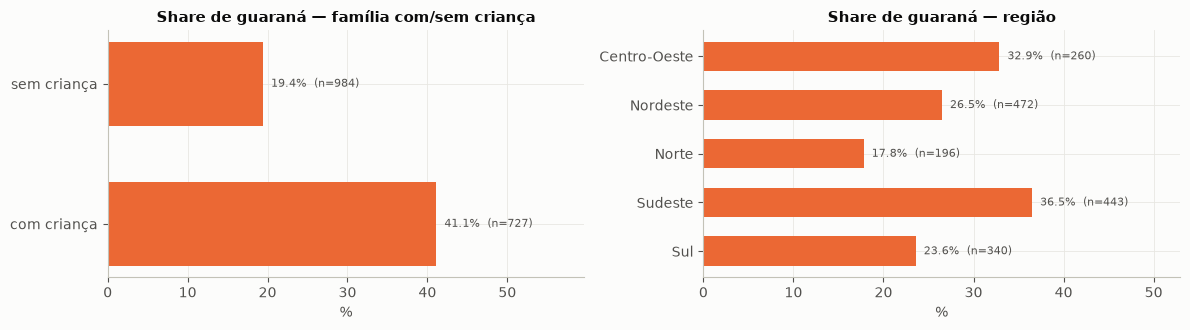

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
r = resumo(base, "tem_crianca")
r["tem_crianca"] = r["tem_crianca"].map({0: "sem criança", 1: "com criança"})
barras(axes[0], r, "share_guarana", "tem_crianca", "Share de guaraná — família com/sem criança", cor=LARANJA)
r = resumo(base, "regiao")
barras(axes[1], r, "share_guarana", "regiao", "Share de guaraná — região", cor=LARANJA)
plt.tight_layout()
plt.show()

**Famílias com criança** escolhem guaraná na pizza com o dobro da frequência das famílias sem criança — um sinal forte do **job "jantar em família"** (notebook 04).

## 5. Matriz de oportunidade (segmento = região × classe de renda)

Cruzamos as duas perguntas do negócio em um só gráfico:
- **eixo x — taxa de pizza:** quanto a ocasião acontece no segmento;
- **eixo y — share de guaraná:** quanto o Guaraná já está nela.

O quadrante **"pizza alta, guaraná baixo"** é onde a Ambev tem mais a ganhar (**Conquistar**).
Linhas de corte = média Brasil. Só mostramos segmentos com pelo menos 30 ocasiões de pizza com refri.

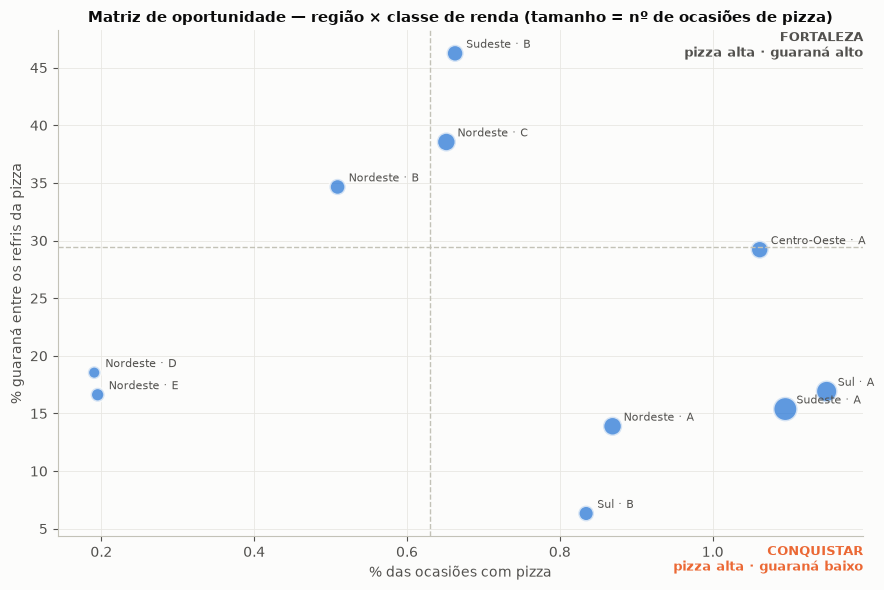

,regiao,classe_renda,ocasioes,n_pizza,taxa_pizza,attach_refri,share_guarana,n_pizza_refri
24,Sul,A,15905,164,1.15%,33.3%,16.9%,42
19,Sudeste,A,23301,209,1.10%,20.1%,15.4%,46
4,Centro-Oeste,A,12735,113,1.06%,23.1%,29.2%,34
9,Nordeste,A,15314,128,0.87%,38.7%,13.9%,52
23,Sul,B,13049,87,0.83%,40.7%,6.3%,33
18,Sudeste,B,22470,102,0.66%,33.8%,46.2%,30
7,Nordeste,C,26031,127,0.65%,43.9%,38.6%,60
8,Nordeste,B,18951,92,0.51%,60.4%,34.6%,59
5,Nordeste,E,36308,68,0.20%,58.2%,16.6%,40
6,Nordeste,D,32246,57,0.19%,55.1%,18.5%,32


In [7]:
seg = resumo(base, ["regiao", "classe_renda"])
pz_refri = base[(base.y_pizza == 1) & (base.tem_refri == 1)].groupby(["regiao", "classe_renda"], observed=True).size()
seg = seg.merge(pz_refri.rename("n_pizza_refri").reset_index(), on=["regiao", "classe_renda"], how="left")
seg_ok = seg[seg["n_pizza_refri"] >= 30].copy()

x_corte = geral["taxa_pizza"].iat[0] * 100
pr_all = base[(base.y_pizza == 1) & (base.tem_refri == 1)]
y_corte = media_ponderada(pr_all, "tem_guarana") * 100

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(seg_ok["taxa_pizza"] * 100, seg_ok["share_guarana"] * 100, s=seg_ok["n_pizza"] * 1.5,
           color=AZUL, alpha=0.75, edgecolor="#fcfcfb", linewidth=2)
for _, r_ in seg_ok.iterrows():
    ax.annotate(f"{r_['regiao']} · {r_['classe_renda']}", (r_["taxa_pizza"] * 100, r_["share_guarana"] * 100),
                textcoords="offset points", xytext=(8, 4), fontsize=8, color=CINZA)
ax.axvline(x_corte, color="#c3c2b7", lw=1, ls="--")
ax.axhline(y_corte, color="#c3c2b7", lw=1, ls="--")
xmax, ymax = ax.get_xlim()[1], ax.get_ylim()[1]
ax.text(xmax, 1, "CONQUISTAR\npizza alta · guaraná baixo", ha="right", va="bottom", fontsize=9, fontweight="bold", color=LARANJA)
ax.text(xmax, ymax, "FORTALEZA\npizza alta · guaraná alto", ha="right", va="top", fontsize=9, fontweight="bold", color=CINZA)
ax.set_xlabel("% das ocasiões com pizza")
ax.set_ylabel("% guaraná entre os refris da pizza")
ax.set_title("Matriz de oportunidade — região × classe de renda (tamanho = nº de ocasiões de pizza)")
plt.tight_layout()
plt.show()
seg_ok.sort_values("taxa_pizza", ascending=False).style.format(fmt)

Essa matriz vira uma **regra do Decision Engine** e uma tela do site.

## 6. Features territoriais externas (por UF)

Trazemos para cada UF:
- **pizzarias por 100 mil habitantes** (OpenStreetMap) → oferta de pizza / delivery;
- **população** e **renda média per capita** (SIDRA/IBGE, 2018 — mesmo período da POF).

**Por que isso importa:** na validação por região (notebook 03), o modelo testa em UFs que **nunca viu**. Saber "é a UF 35" não ajuda numa UF nova; já "tem 12 pizzarias por 100 mil hab. e renda de R$1.900" **transfere** para qualquer lugar.

**Limitação:** o OSM é de hoje (2026) e a POF é de 2017-18; o OSM tem cobertura desigual entre estados. Usamos como **indicador relativo** de oferta, não como contagem exata.

In [8]:
terr_path = ROOT / "data" / "external" / "territorio_uf.csv"
terr = pd.read_csv(terr_path, dtype={"uf": str})
terr

,uf,sigla,pizzarias_osm,populacao,renda_media_pc_uf,pizzarias_100k
0,11,RO,16,1757589,1070,0.910338
1,12,AC,4,869265,856,0.460159
2,13,AM,45,4080611,761,1.102776
3,14,RR,32,576568,1173,5.550083
4,15,PA,96,8513497,813,1.127621
5,16,AP,18,829494,821,2.169998
6,17,TO,15,1555229,997,0.964488
7,21,MA,89,7035055,585,1.265093
8,22,PI,118,3264531,777,3.614608
9,23,CE,230,9075649,811,2.534254


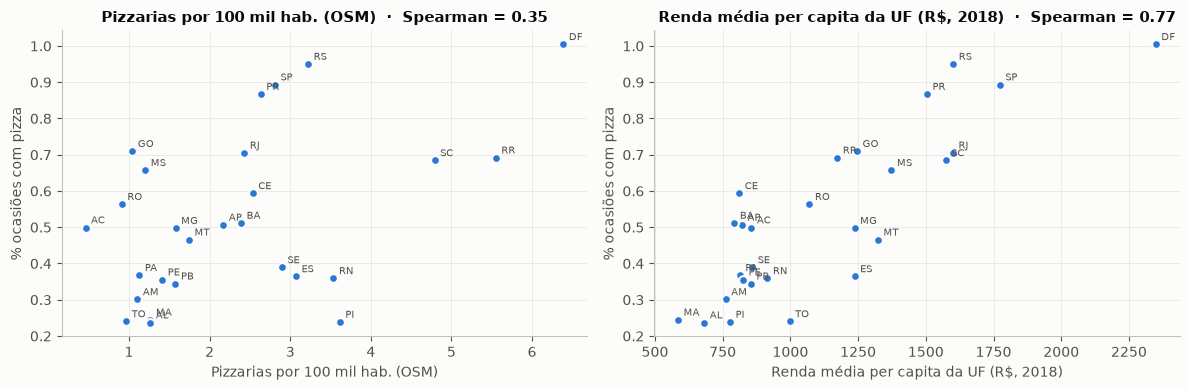

In [9]:
por_uf = resumo(base, "uf").merge(terr, on="uf")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titulo in [(axes[0], "pizzarias_100k", "Pizzarias por 100 mil hab. (OSM)"),
                        (axes[1], "renda_media_pc_uf", "Renda média per capita da UF (R$, 2018)")]:
    ax.scatter(por_uf[col], por_uf["taxa_pizza"] * 100, color=AZUL, s=40, edgecolor="#fcfcfb", linewidth=1.5)
    for _, r_ in por_uf.iterrows():
        ax.annotate(r_["sigla"], (r_[col], r_["taxa_pizza"] * 100), textcoords="offset points", xytext=(4, 3),
                    fontsize=7, color=CINZA)
    corr = por_uf[[col, "taxa_pizza"]].corr(method="spearman").iat[0, 1]
    ax.set_title(f"{titulo}  ·  Spearman = {corr:.2f}")
    ax.set_xlabel(titulo)
    ax.set_ylabel("% ocasiões com pizza")
plt.tight_layout()
plt.show()

Usamos **Spearman** (correlação de ranking) porque são só 27 pontos e a relação pode não ser linear.

## 7. Juntar as features territoriais na base e salvar

In [10]:
base_final = base.merge(terr[["uf", "sigla", "pizzarias_100k", "renda_media_pc_uf", "populacao"]], on="uf", how="left")
base_final["log_populacao_uf"] = np.log10(base_final["populacao"])
base_final = base_final.drop(columns="populacao")
assert base_final["pizzarias_100k"].notna().all()
base_final.to_parquet(ROOT / "data" / "processed" / "base_modelagem.parquet", index=False)
print("Salvo base_modelagem.parquet", base_final.shape)

Salvo base_modelagem.parquet (363412, 35)


## 8. Conclusões da EDA → decisões para o modelo

| Achado | Decisão |
|---|---|
| Noite + fim de semana concentram a pizza | `periodo`, `refeicao`, `fim_de_semana` entram; são também o **baseline** |
| Renda é o fator mais forte depois do horário | `renda_pc` (contínua) entra; `classe_renda` fica para leitura de negócio |
| Fora de casa tem taxa maior por ocasião | `local`/`em_casa` entram como **canal** |
| Criança na família muda o share de guaraná | `tem_crianca`, `n_criancas` entram; vão pesar nos **clusters/jobs** |
| Diferenças regionais | `regiao` + features territoriais numéricas (generalizam para UFs novas) |
| Classe rara (~0,5%) | Métrica principal **PR-AUC**; ajustar o limiar pelo custo dos erros |
| Share de guaraná varia por segmento | Não é feature do modelo; vira **insumo do Decision Engine** |

**Próximo:** notebook 03 — baseline × Regressão Logística × LightGBM, com validação por grupos e por região.